# LightGlue Demo
In this notebook we match two pairs of images using LightGlue with early stopping and point pruning.

In [1]:
# If we are on colab: this clones the repo and installs the dependencies
# from pathlib import Path

# if Path.cwd().name != "LightGlue":
#     !git clone --quiet https://github.com/cvg/LightGlue/
#     %cd LightGlue
#     !pip install --progress-bar off --quiet -e .

from lightglue import LightGlue, SuperPoint
from lightglue.superpoint import sample_descriptors
from lightglue.utils import load_image, rbd
from lightglue import viz2d
import torch
import kornia
from kornia.feature import LoFTR

torch.set_grad_enabled(False)
# images = Path("assets")

/home/tree/anaconda3/envs/light_loftr_glue/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/home/tree/anaconda3/envs/light_loftr_glue/lib/python3.10/site-packages/lightglue/lightglue.py:24: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


# Performing keypoint matching using LoFTR 

In [2]:
# LoFTR from kornia library

def load_torch_image(fname):
    img = kornia.io.load_image(fname, kornia.io.ImageLoadType.RGB32)
    img = img[None]  # 1xCxHxW / fp32 / [0, 1]
    return img

matcher_loftr = LoFTR(pretrained='outdoor').cuda()
img1 = load_torch_image('glue-factory/assets/boat1.png').cuda()
img2 = load_torch_image('glue-factory/assets/boat2.png').cuda()
input_dict = {"image0": kornia.color.rgb_to_grayscale(img1), # LofTR works on grayscale images only 
                "image1": kornia.color.rgb_to_grayscale(img2)}

with torch.no_grad():
        correspondences = matcher_loftr(input_dict)
        mkpts0 = correspondences['keypoints0'].cpu().numpy()
        mkpts1 = correspondences['keypoints1'].cpu().numpy()

## Performing keypoint matching using Lightglue+SP
In this example we use SuperPoint features combined with LightGlue.

In [3]:
# import torch._dynamo

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 'mps', 'cpu'
extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)  # load the extractor
matcher = LightGlue(features="superpoint").eval().to(device)


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /home/tree/.cache/torch/hub/checkpoints/superpoint_v1.pth
100%|██████████| 4.96M/4.96M [00:02<00:00, 2.41MB/s]
Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /home/tree/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth
100%|██████████| 45.3M/45.3M [00:04<00:00, 11.1MB/s]


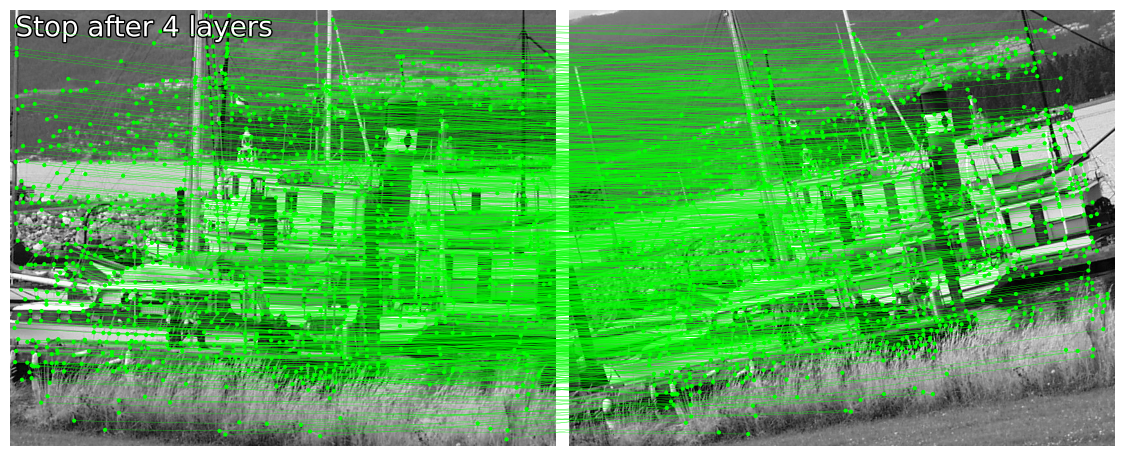

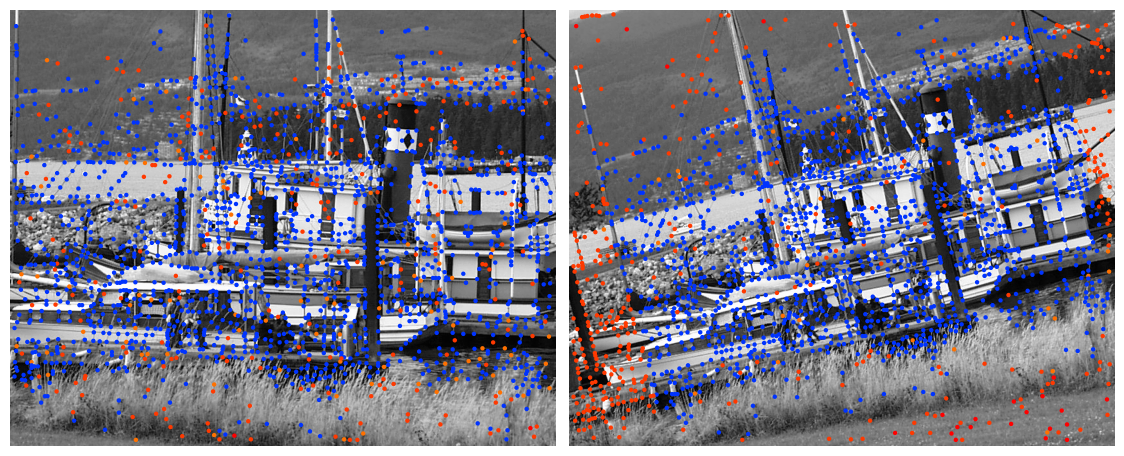

In [5]:
image0 = load_image('glue-factory/assets/boat1.png')
image1 = load_image('glue-factory/assets/boat2.png')

feats0 = extractor.extract(image0.to(device))  # auto-resize the image, disable with resize=None
feats1 = extractor.extract(image1.to(device))

# match the features
matches01 = matcher({'image0': feats0, 'image1': feats1})

feats0, feats1, matches01 = [
    rbd(x) for x in [feats0, feats1, matches01]
]  # remove batch dimension

kpts0, kpts1, matches = feats0["keypoints"], feats1["keypoints"], matches01["matches"]
m_kpts0, m_kpts1 = kpts0[matches[..., 0]], kpts1[matches[..., 1]]

axes = viz2d.plot_images([image0, image1])
viz2d.plot_matches(m_kpts0, m_kpts1, color="lime", lw=0.2)
viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

kpc0, kpc1 = viz2d.cm_prune(matches01["prune0"]), viz2d.cm_prune(matches01["prune1"])
viz2d.plot_images([image0, image1])
viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)

# Using LoFTR keypoints with LightGLue matcher

In [6]:
# We interpolate descriptors at LoFTR keypoints location
# Note : descriptor from SP are probably less suitable at the chosen keypoints location (from LoFTR). Fair comparison would need a complete new training using LoFTR descriptors.
descriptors0  = [
            sample_descriptors(k[None], d[None], 8)[0]
            for k, d in zip(torch.unsqueeze(torch.from_numpy(mkpts0),0).cpu(), torch.unsqueeze(feats0['dense_descriptor_map'],0).cpu())]
descriptors1 = [
            sample_descriptors(k[None], d[None], 8)[0]
            for k, d in zip(torch.unsqueeze(torch.from_numpy(mkpts1),0).cpu(), torch.unsqueeze(feats1['dense_descriptor_map'],0).cpu())]

feats0['descriptors']= torch.stack(descriptors0, 0).transpose(-1, -2).contiguous().to(device)
feats0['keypoints'] = torch.unsqueeze(torch.from_numpy(mkpts0),0).to(device)
feats0['keypoint_scores'] = correspondences['confidence'].to(device)

feats1['descriptors'] = torch.stack(descriptors1, 0).transpose(-1, -2).contiguous().to(device)
feats1['keypoints'] = torch.unsqueeze(torch.from_numpy(mkpts1),0).to(device)
feats1['keypoint_scores'] = correspondences['confidence'].to(device)


KeyError: 'dense_descriptor_map'

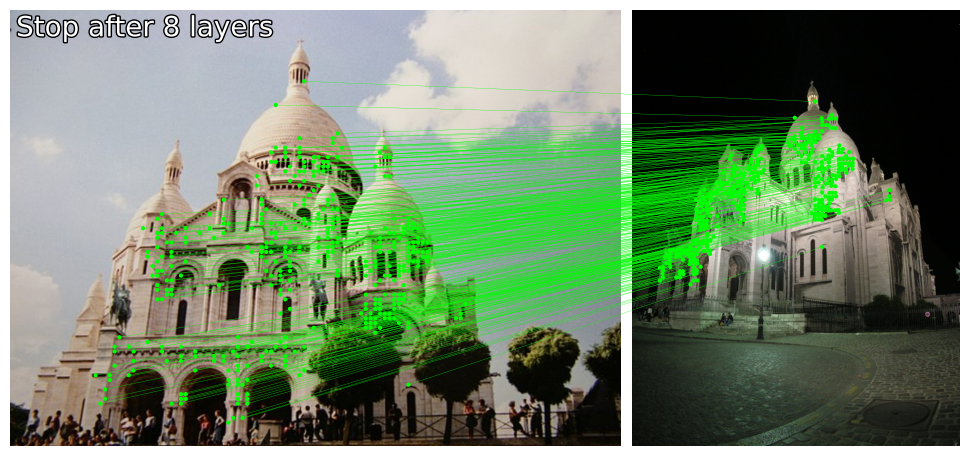

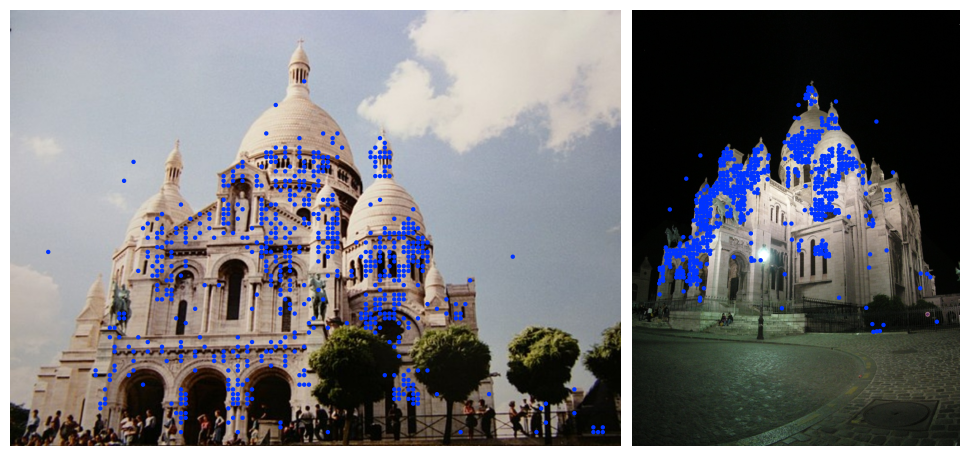

In [45]:
# match the features
matches01 = matcher({'image0': feats0, 'image1': feats1})

feats0, feats1, matches01 = [
    rbd(x) for x in [feats0, feats1, matches01]
]  # remove batch dimension

kpts0, kpts1, matches = feats0["keypoints"], feats1["keypoints"], matches01["matches"]
m_kpts0, m_kpts1 = kpts0[matches[..., 0]], kpts1[matches[..., 1]]

axes = viz2d.plot_images([image0, image1])
viz2d.plot_matches(m_kpts0, m_kpts1, color="lime", lw=0.2)
viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

kpc0, kpc1 = viz2d.cm_prune(matches01["prune0"]), viz2d.cm_prune(matches01["prune1"])
viz2d.plot_images([image0, image1])
viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)